# EcoVision AI — Waste Classification and Disposal Guidance

## 1. Project Overview

EcoVision AI is a computer vision project that classifies waste images into six categories: cardboard, glass, metal, paper, plastic, and trash.

The system will use deep learning and transfer learning to predict the waste category from an uploaded image. It will also provide relevant disposal guidance based on the predicted category.

## 2. Project Objectives

- Classify waste images into six categories.
- Train and evaluate a deep learning model using transfer learning.
- Measure performance using class-wise precision, recall, macro F1-score, and a confusion matrix.
- Handle uncertain predictions responsibly.
- Build a simple interface for image upload, classification, and disposal guidance.

## 3. Dataset

The project uses the TrashNet dataset, containing 2,527 images across six waste categories.

## 4. Project Workflow

1. Dataset exploration and validation
2. Data preprocessing and splitting
3. Baseline model development
4. Transfer learning
5. Model evaluation and error analysis
6. Confidence-aware predictions
7. User interface and disposal guidance

## 5. Limitations

The dataset contains waste images photographed against relatively plain backgrounds. Performance on real-world images, mixed waste, and unfamiliar environments must be evaluated separately.


# Importing Libraries

In [ ]:
# Import the libraries needed for dataset handling and exploration

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile

from PIL import Image

print("Basic project libraries imported successfully!")


Basic project libraries imported successfully!


# Importing Dataset

## Locate the dataset ZIP

In [ ]:
zip_path = Path("/content/EcoVision Data.zip")

if zip_path.exists():
  print("Dataset ZIP found !")
  print(f"File Size : {zip_path.stat().st_size/(1024*1024):.2f} MB")
else:
  print("Dataset ZIP not found !")

Dataset ZIP not found !


## Dataset Extraction

In [ ]:
extract_dir = Path("/content/EcoVisionData")

if not extract_dir.exists():
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

    print("Dataset Extracted Succesfully !")

else:
  print("Extraction Folder Already Exists !")


data_dir = extract_dir/"EcoVision Data"

print("\nDataset Folder Found : ", data_dir.exists())
print("\ncategories : \n", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

Dataset Extracted Succesfully !

Dataset Folder Found :  True

categories : 
 ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


# Dataset Exploration

## Waste Categories & Counts

In [ ]:
class_counts = {}

for class_name in sorted(p.name for p in data_dir.iterdir() if p.is_dir()):
  class_folder = data_dir/class_name
  image_files = list(class_folder.glob("*.jpg"))

  class_counts[class_name] = len(image_files)

for class_name, image_count in class_counts.items():
  print(f'{class_name} : {image_count}')

print("\nTotal Images : ", sum(class_counts.values()))


cardboard : 403
glass : 501
metal : 410
paper : 594
plastic : 482
trash : 137

Total Images :  2527


## Visulaization of waste categories & Counts

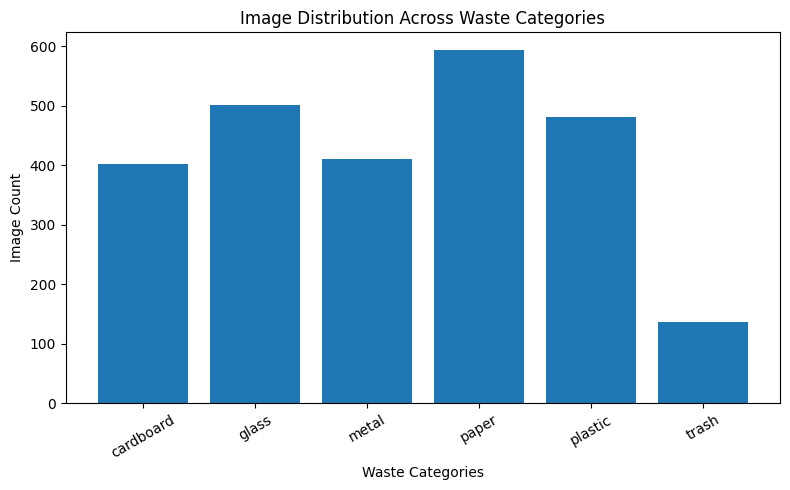

In [ ]:
class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns = ['Categories','Image Count']
)

plt.figure(figsize = (8,5))

plt.bar(
    class_counts_df['Categories'],
    class_counts_df['Image Count']
)

plt.title("Image Distribution Across Waste Categories")
plt.xlabel('Waste Categories')
plt.ylabel('Image Count')
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

## Image Extensions and Modes

In [ ]:
file_extensions = Counter()
image_modes = Counter()

for class_folder in data_dir.iterdir():
    if class_folder.is_dir():
        for image_path in class_folder.iterdir():
            if image_path.is_file():
                file_extensions[image_path.suffix.lower()] += 1

                try:
                    with Image.open(image_path) as img:
                        image_modes[img.mode] += 1
                except Exception as error:
                    print(f"Could not open: {image_path.name} — {error}")

print("File extensions:")
print(file_extensions)

print("\nImage colour modes:")
print(image_modes)

File extensions:
Counter({'.jpg': 2527})

Image colour modes:
Counter({'RGB': 2527})


# Dataset Preparation

In [ ]:
image_paths = []
labels = []

for class_folder in sorted(data_dir.iterdir()):
  if class_folder.is_dir():
    class_name = class_folder.name

  for image_path in class_folder.glob("*.jpg"):
    image_paths.append(image_path)
    labels.append(class_name)

print("Total Image Paths : ", len(image_paths))
print("Total labels : ", len(labels))

print("\nFirst Image Path : ",image_paths[0])
print("First Label : ",labels[0])

Total Image Paths :  2527
Total labels :  2527

First Image Path :  /content/EcoVisionData/EcoVision Data/cardboard/cardboard163.jpg
First Label :  cardboard


## Split the Dataset

In [ ]:
x_train, x_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size = 0.3,
    stratify = labels,
    random_state = 20
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size = 0.5,
    stratify = y_temp,
    random_state = 20
)

print("Succesfully splitted the data into : \n Training : 70%\n Validation : 15%\n Test : 15%")

Succesfully splitted the data into : 
 Training : 70%
 Validation : 15%
 Test : 15%


## Validatiing the Split

In [ ]:
print("Training Images : ", len(x_train))
print("Validation Images : ", len(x_val))
print("Test Images : ", len(x_test))

print("Total Images : ", len(x_train) + len(x_val) + len(x_test))

Training Images :  1768
Validation Images :  379
Test Images :  380
Total Images :  2527


## Verifying Class Distribution

In [ ]:
print("Training set:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation set:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTest set:")
print(pd.Series(y_test).value_counts().sort_index())

Training set:
cardboard    282
glass        350
metal        287
paper        416
plastic      337
trash         96
Name: count, dtype: int64

Validation set:
cardboard    61
glass        75
metal        61
paper        89
plastic      72
trash        21
Name: count, dtype: int64

Test set:
cardboard    60
glass        76
metal        62
paper        89
plastic      73
trash        20
Name: count, dtype: int64


# Image Preprocessing

## Define image transformations

In [ ]:
from torchvision import transforms
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
mean = weights.transforms().mean
std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std = std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std = std)
])

print("Training transformations:")
print(train_transform)

print("\nValidation/Test transformations:")
print(eval_transform)

print("\nNormalization mean:", mean)
print("Normalization std:", std)


Training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation/Test transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Normalization mean: [0.485, 0.456, 0.406]
Normalization std: [0.229, 0.224, 0.225]


# Data Preprocessing

## Data Preprocessing

In [ ]:
classes = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]

class_to_idx = {
    class_name: index
    for index, class_name in enumerate(classes)
}

idx_to_class = {
    index: class_name
    for class_name, index in class_to_idx.items()
}

print("Class mapping:", class_to_idx)

Class mapping: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [ ]:
print("Training labels:", y_train[:10])
print("Label type:", type(y_train[0]))

Training labels: ['glass', 'paper', 'paper', 'glass', 'metal', 'cardboard', 'paper', 'paper', 'trash', 'glass']
Label type: <class 'str'>


## Create the custom PyTorch Dataset

In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class WasteDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        # Load the image
        image = Image.open(self.image_paths[index]).convert("RGB")

        # Convert the category name to a numeric label
        label = class_to_idx[self.labels[index]]

        # Apply the appropriate image transformations
        if self.transform is not None:
            image = self.transform(image)

        return image, label


In [ ]:
train_dataset = WasteDataset(
    x_train, y_train, transform=train_transform
)

val_dataset = WasteDataset(
    x_val, y_val, transform=eval_transform
)

test_dataset = WasteDataset(
    x_test, y_test, transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Training samples: 1768
Validation samples: 379
Test samples: 380


In [ ]:
image_tensor, label = train_dataset[5]

print("Image tensor shape:", image_tensor.shape)
print("Image tensor dtype:", image_tensor.dtype)
print("Numeric label:", label)
print("Waste category:", idx_to_class[label])

Image tensor shape: torch.Size([3, 224, 224])
Image tensor dtype: torch.float32
Numeric label: 0
Waste category: cardboard


## Create DataLoaders

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 56
Validation batches: 12
Test batches: 12


# Initial Model & Training

## Load the pretrained ResNet18 model

In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = models.resnet18(weights = weights)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 236MB/s]


Linear(in_features=512, out_features=1000, bias=True)


In [ ]:
num_classes = 6

model.fc = nn.Linear(
    in_features = model.fc.in_features,
    out_features = num_classes
)

print(model.fc)

Linear(in_features=512, out_features=6, bias=True)


## Define the loss function and optimizer

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

## Choose the Device

In [ ]:
print("GPU available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Using device:", device)

GPU available: True
Using device: cuda


In [ ]:
print("Model device:", next(model.parameters()).device)
print("GPU name:", torch.cuda.get_device_name(0))

Model device: cuda:0
GPU name: Tesla T4


## Training Loop

In [ ]:

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_images = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct_predictions += (predictions == labels).sum().item()
        total_images += labels.size(0)

    epoch_loss = running_loss / total_images
    epoch_accuracy = correct_predictions / total_images

    return epoch_loss, epoch_accuracy


In [ ]:
train_loss, train_accuracy = train_one_epoch(
    model=model,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device
)

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.2%}")

Training Loss: 1.0341
Training Accuracy: 63.74%


## Evaluate on the validation set

In [ ]:

def evaluate(model, data_loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_images = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct_predictions += (predictions == labels).sum().item()
            total_images += labels.size(0)

    epoch_loss = running_loss / total_images
    epoch_accuracy = correct_predictions / total_images

    return epoch_loss, epoch_accuracy


In [ ]:
val_loss, val_accuracy = evaluate(
    model=model,
    data_loader=val_loader,
    criterion=criterion,
    device=device
)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2%}")

Validation Loss: 0.8966
Validation Accuracy: 67.02%


## Train for Multiple Epochs

In [ ]:

num_epochs = 5

for epoch in range(2, num_epochs + 1):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    print(f"Epoch [{epoch}/{num_epochs}]")
    print(f"  Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2%}")
    print(f"  Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_accuracy:.2%}")
    print("-" * 55)


Epoch [2/5]
  Train Loss: 0.6524 | Train Accuracy: 77.43%
  Val Loss:   1.6375 | Val Accuracy:   58.58%
-------------------------------------------------------
Epoch [3/5]
  Train Loss: 0.6336 | Train Accuracy: 77.32%
  Val Loss:   0.8075 | Val Accuracy:   73.61%
-------------------------------------------------------
Epoch [4/5]
  Train Loss: 0.4848 | Train Accuracy: 84.11%
  Val Loss:   0.7120 | Val Accuracy:   74.67%
-------------------------------------------------------
Epoch [5/5]
  Train Loss: 0.4228 | Train Accuracy: 85.97%
  Val Loss:   0.6313 | Val Accuracy:   74.93%
-------------------------------------------------------


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Validation predictions collected:", len(all_predictions))
print("Validation labels collected:", len(all_labels))


Validation predictions collected: 379
Validation labels collected: 379


In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

   cardboard     0.9811    0.8525    0.9123        61
       glass     1.0000    0.3733    0.5437        75
       metal     0.5357    0.9836    0.6936        61
       paper     0.9221    0.7978    0.8554        89
     plastic     0.6897    0.8333    0.7547        72
       trash     0.5909    0.6190    0.6047        21

    accuracy                         0.7493       379
   macro avg     0.7866    0.7433    0.7274       379
weighted avg     0.8223    0.7493    0.7438       379



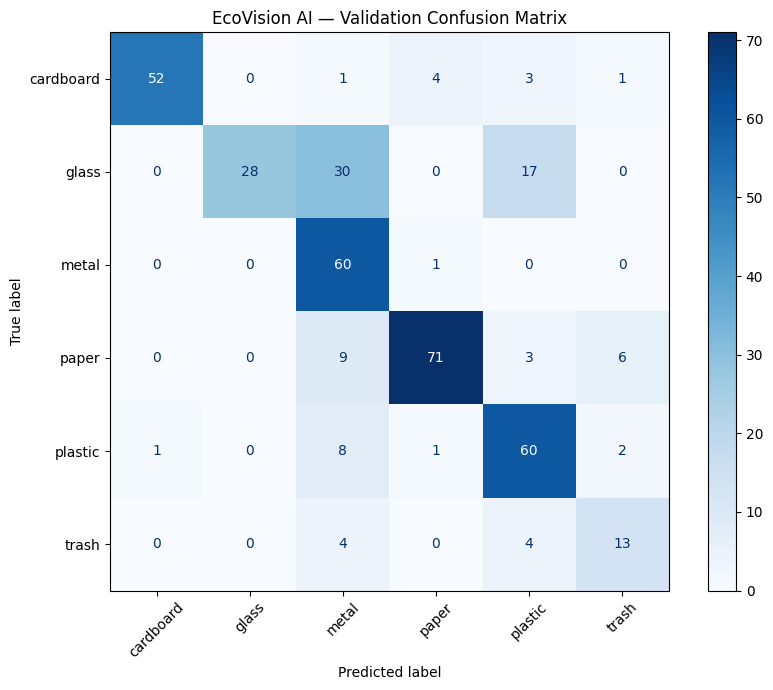

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("EcoVision AI — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
torch.save(model.state_dict(), "ecovision_resnet18_baseline.pth")

print("Baseline model saved.")

Baseline model saved.


# Frozen Backbone Experiment

In [ ]:
# Freeze all model parameters
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the final classification layer
for param in model.fc.parameters():
    param.requires_grad = True

# Check which parameters are trainable
trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 3078


In [ ]:
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Optimizer configured for the final classification layer.")

Optimizer configured for the final classification layer.


In [ ]:
num_epochs = 5

for epoch in range(1, num_epochs + 1):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    print(f"Epoch [{epoch}/{num_epochs}]")
    print(f"  Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2%}")
    print(f"  Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_accuracy:.2%}")
    print("-" * 55)


Epoch [1/5]
  Train Loss: 0.2689 | Train Accuracy: 90.61%
  Val Loss:   0.4058 | Val Accuracy:   84.43%
-------------------------------------------------------
Epoch [2/5]
  Train Loss: 0.2586 | Train Accuracy: 90.95%
  Val Loss:   0.4074 | Val Accuracy:   84.43%
-------------------------------------------------------
Epoch [3/5]
  Train Loss: 0.2450 | Train Accuracy: 91.86%
  Val Loss:   0.4267 | Val Accuracy:   83.91%
-------------------------------------------------------
Epoch [4/5]
  Train Loss: 0.2400 | Train Accuracy: 92.14%
  Val Loss:   0.4366 | Val Accuracy:   85.75%
-------------------------------------------------------
Epoch [5/5]
  Train Loss: 0.2272 | Train Accuracy: 92.48%
  Val Loss:   0.4386 | Val Accuracy:   83.38%
-------------------------------------------------------


In [ ]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Validation predictions collected:", len(all_predictions))

Validation predictions collected: 379


In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

   cardboard     0.9322    0.9016    0.9167        61
       glass     0.8548    0.7067    0.7737        75
       metal     0.7794    0.8689    0.8217        61
       paper     0.8515    0.9663    0.9053        89
     plastic     0.7639    0.7639    0.7639        72
       trash     0.8235    0.6667    0.7368        21

    accuracy                         0.8338       379
   macro avg     0.8342    0.8123    0.8197       379
weighted avg     0.8354    0.8338    0.8314       379



# Final Fine-Tuning

In [ ]:
# Freeze the entire model first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the later ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep the final classification layer trainable
for param in model.fc.parameters():
    param.requires_grad = True

print("Trainable layers: layer4 and fc")

Trainable layers: layer4 and fc


In [ ]:
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

print("Optimizer configured for fine-tuning.")

Optimizer configured for fine-tuning.


In [ ]:
num_epochs = 5
best_val_loss = float("inf")

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    print(f"Epoch [{epoch + 1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
    print("-" * 50)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            model.state_dict(),
            "ecovision_resnet18_best.pth"
        )
        print("Best model checkpoint saved.")

Epoch [1/5]
Train Loss: 0.2170 | Train Acc: 0.9231
Val Loss:   0.4213 | Val Acc:   0.8391
--------------------------------------------------
Best model checkpoint saved.
Epoch [2/5]
Train Loss: 0.1943 | Train Acc: 0.9367
Val Loss:   0.4362 | Val Acc:   0.8417
--------------------------------------------------
Epoch [3/5]
Train Loss: 0.1977 | Train Acc: 0.9355
Val Loss:   0.4246 | Val Acc:   0.8443
--------------------------------------------------
Epoch [4/5]
Train Loss: 0.1848 | Train Acc: 0.9395
Val Loss:   0.3855 | Val Acc:   0.8496
--------------------------------------------------
Best model checkpoint saved.
Epoch [5/5]
Train Loss: 0.1755 | Train Acc: 0.9406
Val Loss:   0.3906 | Val Acc:   0.8496
--------------------------------------------------


In [ ]:
model.load_state_dict(
    torch.load(
        "ecovision_resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best fine-tuned model loaded.")

Best fine-tuned model loaded.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Validation Classification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

Validation Classification Report:

              precision    recall  f1-score   support

   cardboard     0.9322    0.9016    0.9167        61
       glass     0.8451    0.8000    0.8219        75
       metal     0.8182    0.8852    0.8504        61
       paper     0.8737    0.9326    0.9022        89
     plastic     0.7971    0.7639    0.7801        72
       trash     0.7895    0.7143    0.7500        21

    accuracy                         0.8496       379
   macro avg     0.8426    0.8329    0.8369       379
weighted avg     0.8493    0.8496    0.8487       379



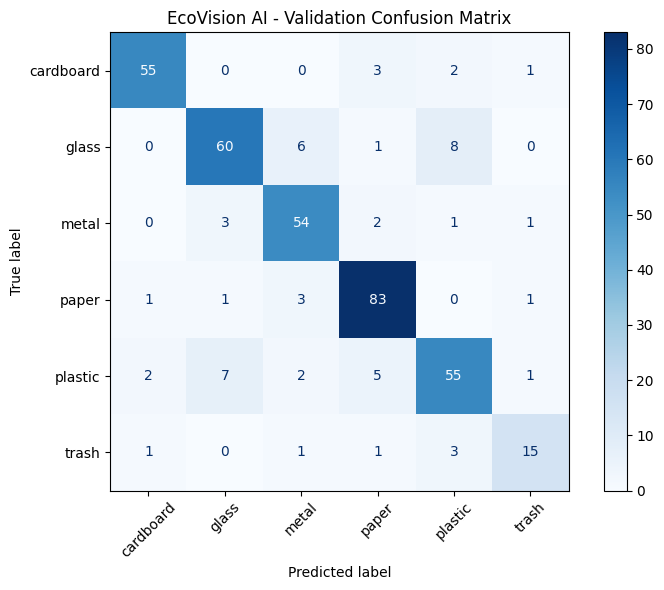

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(8, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("EcoVision AI - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Saving & Final Test Evaluation

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import shutil

save_dir = Path("/content/drive/MyDrive/EcoVisionAI/models")
save_dir.mkdir(parents=True, exist_ok=True)

source_path = Path("ecovision_resnet18_best.pth")
destination_path = save_dir / "ecovision_resnet18_best.pth"

shutil.copy2(source_path, destination_path)

print("Model saved to:", destination_path)
print("File exists:", destination_path.exists())

Model saved to: /content/drive/MyDrive/EcoVisionAI/models/ecovision_resnet18_best.pth
File exists: True


In [ ]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Test Loss: 0.3295
Test Accuracy: 0.8868 (88.68%)


In [ ]:
from sklearn.metrics import classification_report

model.eval()

test_predictions = []
test_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        test_predictions.extend(predictions.cpu().numpy())
        test_labels.extend(labels.numpy())

print("Final Test Classification Report:\n")

print(classification_report(
    test_labels,
    test_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

Final Test Classification Report:

              precision    recall  f1-score   support

   cardboard     0.9310    0.9000    0.9153        60
       glass     0.8846    0.9079    0.8961        76
       metal     0.8421    0.7742    0.8067        62
       paper     0.9121    0.9326    0.9222        89
     plastic     0.9028    0.8904    0.8966        73
       trash     0.7500    0.9000    0.8182        20

    accuracy                         0.8868       380
   macro avg     0.8704    0.8842    0.8758       380
weighted avg     0.8878    0.8868    0.8866       380



In [ ]:
from sklearn.metrics import classification_report
import json

report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

results = {
    "model": "ResNet18",
    "experiment": "Fine-tuning layer4 and fc",
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "classification_report": report
}

results_path = save_dir / "ecovision_test_results.json"

with open(results_path, "w") as file:
    json.dump(results, file, indent=4)

print("Evaluation results saved to:", results_path)

Evaluation results saved to: /content/drive/MyDrive/EcoVisionAI/models/ecovision_test_results.json
